# Day 6 — EDA: what drives wildfires in Lebanon?

**Data:** 488 cells × 5,391 days = 2.63M cell-days (2012–2026). FIRMS fires, MODIS NDVI, Copernicus DEM, Open-Meteo weather (2012–2015 so far).

## Key findings
1. **Extreme imbalance:** 0.20% of cell-days have a fire tomorrow (1 : 494) → PR-AUC and top-k recall, never accuracy.
2. **Industrial hotspots removed:** 959 detections at power plants and cement factories burn year-round → excluded from the target.
3. **Season:** Jun–Oct, cell-days peak in Sep; fire season is ~4× riskier, but still 99.6% negative.
4. **Conflict shift:** the south holds ~20% of fires normally, but 47% in 2024 and 50% in 2026 → report metrics by region and period.
5. **Fires cluster:** fire today → 30× lift, last 7 days → 11×, burning neighbor → 7×. But ~3/4 of fires start in quiet cells.
6. **Elevation** is the strongest static signal (Spearman −0.67); south-facing slopes show no clear link alone.
7. **Vegetation is a hump:** medium NDVI burns ~10× more than bare land and ~2× more than the greenest → tree models.
8. **Weather works as anomalies, not raw values:** humidity below the cell's normal → 3.7× more fires; VPD/ET0 above normal → ~2.5×.

## → Day 7 feature list
- Fire history: fire today, fires in last 3/7 days, burning neighbors, past fire rate per cell (past data only)
- Weather: raw values + anomalies vs past-only cell/month normals, days since last rain
- Vegetation: latest NDVI, NDVI age, NDVI drop from spring peak
- Static: elevation, slope, aspect, land_frac
- Calendar: day of year (cyclical)

## → Day 8–10 decisions
- Baseline to beat: "fire today → fire tomorrow"
- Class weights for imbalance, no resampling before the split
- Validate on later years; report scores separately for south vs rest and war vs normal periods

In [1]:
from pathlib import Path  # clean file paths

import geopandas as gpd  # maps and the grid
import matplotlib.pyplot as plt  # charts
import numpy as np  # math helpers
import pandas as pd  # tables

ROOT = Path("..")  # the notebook runs inside notebooks/, so the project root is one level up
DATA = ROOT / "data" / "processed"  # where all cleaned tables live
FIG_DIR = ROOT / "reports" / "figures"  # where charts get saved for the README
FIG_DIR.mkdir(parents=True, exist_ok=True)  # create the folder if it doesn't exist

plt.style.use("seaborn-v0_8-whitegrid")  # clean style with a light grid
plt.rcParams["figure.figsize"] = (10, 4)  # default chart size: wide and short
plt.rcParams["figure.dpi"] = 110  # slightly sharper charts in the notebook
pd.set_option("display.max_columns", 30)  # show all columns instead of "..."


def save_fig(name):  # save the current chart under reports/figures
    plt.tight_layout()  # stop labels from being cut off
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")  # high-quality PNG for the README
    print("Saved", name)  # confirm

In [2]:
fires = pd.read_parquet(DATA / "fires_with_cells.parquet")  # fire detections with cell_id
grid = gpd.read_file(DATA / "lebanon_grid.gpkg")  # 488 cells with their shapes, for maps
terrain = pd.read_parquet(DATA / "terrain.parquet")  # per-cell terrain stats
ndvi = pd.read_parquet(DATA / "ndvi.parquet")  # NDVI per cell per 8-day composite
weather = pd.read_parquet(DATA / "weather_daily.parquet")  # daily weather per cell (2012–2015 for now)

for name, df in [("fires", fires), ("grid", grid), ("terrain", terrain), ("ndvi", ndvi), ("weather", weather)]:  # loop over every table
    print(f"{name:8s} {df.shape}")  # name padded to 8 characters, then (rows, cols)

print(fires["hotspot"].value_counts())  # check what this Day 3 flag contains before we use the fires

fires    (9527, 11)
grid     (488, 5)
terrain  (488, 9)
ndvi     (323544, 6)
weather  (672786, 9)
hotspot
False    8568
True      959
Name: count, dtype: int64


## 1. Are flagged hotspots really non-wildfire heat sources?

Saved 01_hotspot_monthly_profile


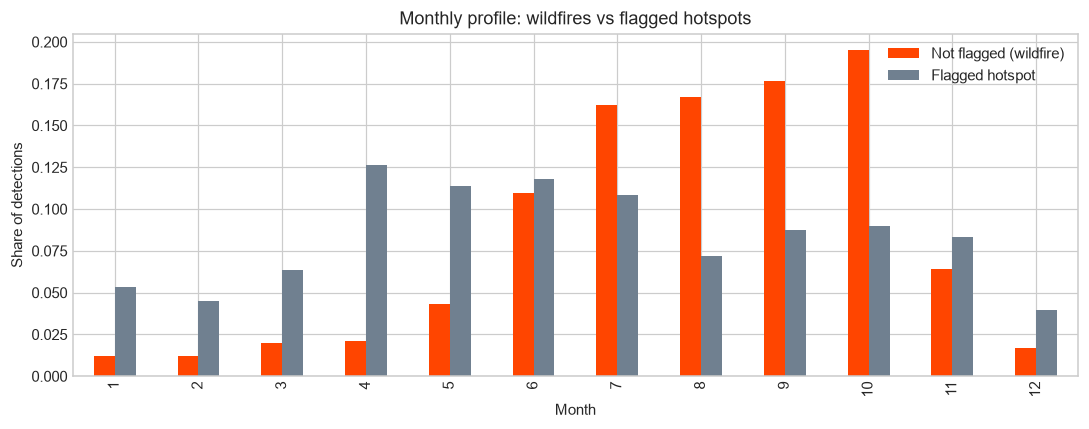

     lat    lon  detections  years  cell_id
0  34.45  35.85         136     15      242
1  33.50  35.34          93     14       37
2  34.31  35.72          92     14      164
3  33.63  35.42          71     13       53
4  33.75  35.50          69      7       72
5  34.46  35.89          53     11      242
6  34.49  36.30          49     11      413
7  34.47  35.89          44     10      242


In [3]:
fires["month"] = fires["acq_date"].dt.month  # calendar month of each detection (1-12)
monthly = fires.groupby(["month", "hotspot"]).size().unstack(fill_value=0)  # count per month, one column for flagged and one for not flagged
monthly_share = monthly / monthly.sum()  # turn counts into the share of each group's detections per month, so both fit one chart

monthly_share.plot(kind="bar", color={False: "orangered", True: "slategray"})  # side-by-side bars: wildfires orange, hotspots gray
plt.title("Monthly profile: wildfires vs flagged hotspots")  # chart title
plt.xlabel("Month")  # x-axis label
plt.ylabel("Share of detections")  # y-axis label
plt.legend(["Not flagged (wildfire)", "Flagged hotspot"])  # readable legend labels
save_fig("01_hotspot_monthly_profile")  # save for the README
plt.show()  # display the chart

spots = (  # summarize each flagged ~1 km spot
    fires[fires["hotspot"]]  # only flagged detections
    .assign(lat=lambda d: d["latitude"].round(2), lon=lambda d: d["longitude"].round(2))  # same ~1 km rounding as Day 3
    .groupby(["lat", "lon"])  # one group per spot
    .agg(detections=("acq_date", "size"), years=("acq_date", lambda s: s.dt.year.nunique()), cell_id=("cell_id", "first"))  # size, number of active years, and the cell it sits in
    .sort_values("detections", ascending=False)  # biggest first
    .reset_index()  # lat and lon back to normal columns
)  # end of summary
print(spots.head(8))  # the 8 busiest flagged spots

**Finding:** Flagged hotspots burn all year (flat monthly profile), while real wildfires peak Jul–Oct.
The busiest flagged spots sit on power plants and cement factories (Deir Ammar, Zahrani, Chekka, Jiyeh).
→ Day 7: exclude `hotspot == True` detections from the fire target.

## 2. Target: fire in the cell tomorrow

In [4]:
real = fires[~fires["hotspot"]]  # keep only real wildfires (drop the industrial hotspots)
fire_days = real[["cell_id", "acq_date"]].drop_duplicates().rename(columns={"acq_date": "date"})  # one row per cell per day with at least one fire
fire_days["fire"] = 1  # mark those cell-days as burning

dates = pd.date_range(fires["acq_date"].min(), fires["acq_date"].max(), freq="D")  # every day from the first to the last detection
panel = pd.MultiIndex.from_product([grid["cell_id"], dates], names=["cell_id", "date"]).to_frame(index=False)  # every cell × every day, as a table

panel = panel.merge(fire_days, on=["cell_id", "date"], how="left")  # attach the fire mark where it exists
panel["fire"] = panel["fire"].fillna(0).astype("int8")  # no fire = 0; int8 uses 8x less memory than the default
panel = panel.sort_values(["cell_id", "date"]).reset_index(drop=True)  # order by cell, then by day, so "tomorrow" is the next row
panel["fire_tomorrow"] = panel.groupby("cell_id")["fire"].shift(-1)  # pull the next day's value up, within each cell only
panel = panel.dropna(subset=["fire_tomorrow"])  # the last day of each cell has no tomorrow, so drop it
panel["fire_tomorrow"] = panel["fire_tomorrow"].astype("int8")  # back to small whole numbers

n_pos = int(panel["fire_tomorrow"].sum())  # number of positive rows (fire tomorrow)
rate = panel["fire_tomorrow"].mean()  # share of positive rows
print(f"Rows: {len(panel):,}")  # total cell-days
print(f"Positives: {n_pos:,} ({rate:.3%})")  # how many fire-tomorrow rows, and their percent
print(f"Negatives per positive: {(1 - rate) / rate:,.0f}")  # imbalance ratio: how many no-fire rows for each fire row

season = panel["date"].dt.month.between(7, 10)  # True for July to October
print(f"Positive rate in fire season (Jul-Oct): {panel.loc[season, 'fire_tomorrow'].mean():.3%}")  # rate during the season
print(f"Positive rate outside the season: {panel.loc[~season, 'fire_tomorrow'].mean():.3%}")  # rate for the rest of the year

Rows: 2,630,808
Positives: 5,313 (0.202%)
Negatives per positive: 494
Positive rate in fire season (Jul-Oct): 0.390%
Positive rate outside the season: 0.104%


**Finding:** 2.63M cell-days, only 0.20% positive (1 fire per ~494 non-fire days).
Fire season (Jul–Oct) is ~4× riskier than the rest of the year, but still 99.6% negative.
→ Day 8+: no accuracy; use PR-AUC and recall in the top-ranked cells. Handle imbalance with class weights, never by resampling before the split.

## 3. When do fires happen?

Saved 02_fire_timing


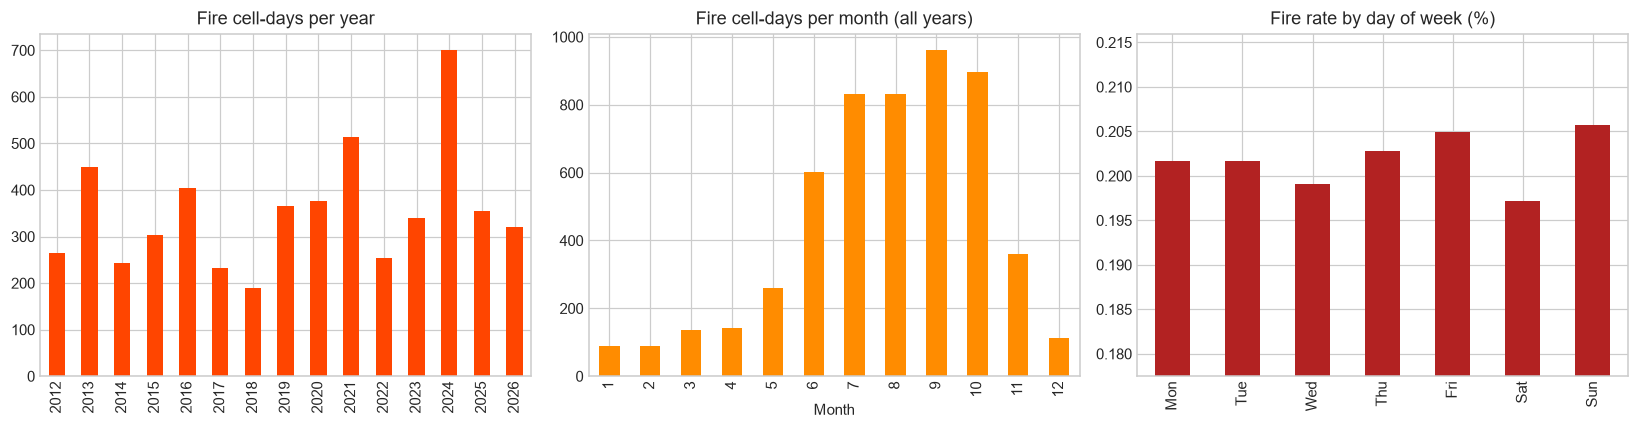

date
2024    701
2021    513
2013    449
2016    405
Name: fire, dtype: int64
Busiest weekday / quietest weekday: 1.04x


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # three charts side by side

yearly = panel.groupby(panel["date"].dt.year)["fire"].sum()  # fire cell-days per year
yearly.plot(kind="bar", ax=axes[0], color="orangered")  # bar per year
axes[0].set_title("Fire cell-days per year")  # title
axes[0].set_xlabel("")  # the years explain themselves

monthly = panel.groupby(panel["date"].dt.month)["fire"].sum()  # fire cell-days per calendar month, all years together
monthly.plot(kind="bar", ax=axes[1], color="darkorange")  # bar per month
axes[1].set_title("Fire cell-days per month (all years)")  # title
axes[1].set_xlabel("Month")  # x-axis label

dow = panel.groupby(panel["date"].dt.day_of_week)["fire"].mean() * 100  # percent of cell-days burning, per weekday (0 = Monday); day_of_week is the new name
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]  # readable weekday names
dow.plot(kind="bar", ax=axes[2], color="firebrick")  # bar per weekday
axes[2].set_title("Fire rate by day of week (%)")  # title
axes[2].set_ylim(dow.min() * 0.9, dow.max() * 1.05)  # zoom the y-axis so small differences are visible
axes[2].set_xlabel("")  # weekday names explain themselves

save_fig("02_fire_timing")  # save for the README
plt.show()  # display the three charts

print(yearly.sort_values(ascending=False).head(4))  # the 4 worst years
print(f"Busiest weekday / quietest weekday: {dow.max() / dow.min():.2f}x")  # how strong the weekday effect is

**Finding:** Fire season is Jun–Oct (cell-days peak in Sep; detections per fire peak in Oct → bigger fires).
2024 is the worst year by far, likely driven by the southern border war (Oct 2023–Nov 2024), not weather.
Weekday effect is ~1.04× → noise, no weekday feature.

## 4. Where do fires happen?

Saved 03_fire_map


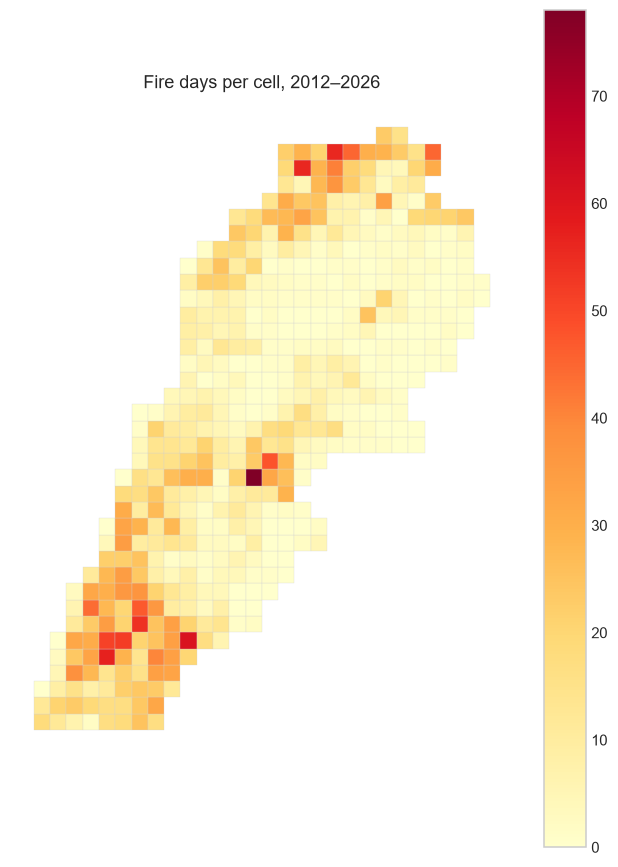

Top 10% of cells hold 35% of fire days
Cells that never burned: 75 of 488

South cells: 64 of 488 (13% of the country)
Share of fire days in the south, per year:
date
2012    0.29
2013    0.20
2014    0.20
2015    0.23
2016    0.23
2017    0.19
2018    0.15
2019    0.25
2020    0.23
2021    0.18
2022    0.14
2023    0.26
2024    0.47
2025    0.26
2026    0.50
Name: cell_id, dtype: float64


In [6]:
fire_counts = panel.groupby("cell_id")["fire"].sum().rename("fire_days")  # total fire days per cell over all years
grid_f = grid.merge(fire_counts, left_on="cell_id", right_index=True)  # attach the counts to the cell shapes

ax = grid_f.plot(column="fire_days", cmap="YlOrRd", legend=True, figsize=(6, 8), edgecolor="lightgray", linewidth=0.2)  # color each cell by fire days
ax.set_title("Fire days per cell, 2012–2026")  # title
ax.set_axis_off()  # hide the meter coordinates, they add nothing
save_fig("03_fire_map")  # save for the README
plt.show()  # display the map

sorted_counts = fire_counts.sort_values(ascending=False)  # busiest cells first
top10 = sorted_counts.head(len(sorted_counts) // 10).sum() / sorted_counts.sum()  # share of fire days held by the top 10% of cells
print(f"Top 10% of cells hold {top10:.0%} of fire days")  # how concentrated fires are
print(f"Cells that never burned: {(fire_counts == 0).sum()} of {len(fire_counts)}")  # cells with zero fire days

south_cells = grid.loc[grid["lat"] < 33.35, "cell_id"]  # cells within roughly 25 km of the southern border
burning = panel[panel["fire"] == 1]  # only the cell-days that burned
south_share = burning.groupby(burning["date"].dt.year)["cell_id"].apply(lambda s: s.isin(south_cells).mean())  # share of each year's fire days in the south
print(f"\nSouth cells: {len(south_cells)} of {len(grid)} ({len(south_cells) / len(grid):.0%} of the country)")  # how big the south zone is
print("Share of fire days in the south, per year:")  # header
print(south_share.round(2))  # one share per year

In [7]:
south_burning = burning[burning["cell_id"].isin(south_cells)]  # fire days in southern cells only
by_month = south_burning.groupby([south_burning["date"].dt.year, south_burning["date"].dt.month]).size().unstack(fill_value=0)  # rows = years, columns = months
print(by_month.loc[[2022, 2023, 2024, 2025, 2026]])  # compare a normal year with the war years and this year

date  1   2   3   4   5   6   7   8   9    10  11  12
date                                                 
2022   0   0   2   3   4   2   7   3  10    2   1   1
2023   2   6   5   7   6   2   7   9  13   21   7   3
2024   0   0   0   2  15  49  23  27  46  154  10   2
2025   1   0   2   6  14   8   6   8  10   14  21   2
2026   1   0   0   0   5  29  41  38  34   11   0   0


**Finding:** The south is ~13% of cells but ~20% of fire days in normal years.
That share jumps to 47% in 2024 (154 southern fire days in Oct 2024 alone) and 50% in 2026 (4–10× normal every month Jun–Sep).
These spikes are not explained by season alone → a distribution shift.
→ Keep the data; add recent-nearby-fire features (Day 7); report metrics by region and period (Day 10).

## 5. Persistence and spread

In [8]:
nbrs = gpd.sjoin(grid[["cell_id", "geometry"]], grid[["cell_id", "geometry"]], predicate="touches")  # pair every cell with each cell it touches (edges or corners)
nbrs = nbrs[["cell_id_left", "cell_id_right"]].rename(columns={"cell_id_left": "cell_id", "cell_id_right": "nbr_id"})  # clean names: a cell and one of its neighbors
print(f"Average neighbors per cell: {len(nbrs) / len(grid):.1f}")  # inland cells have 8; border and coast cells fewer

nbr_fire = fire_days.rename(columns={"cell_id": "nbr_id"}).merge(nbrs, on="nbr_id")  # for each burning cell-day, list every cell next to it
nbr_fire = nbr_fire[["cell_id", "date"]].drop_duplicates().assign(nbr_fire=1)  # one mark per cell-day that has at least one burning neighbor
panel = panel.drop(columns=["nbr_fire"], errors="ignore")  # remove the column if this cell was run before, to avoid duplicates
panel = panel.merge(nbr_fire, on=["cell_id", "date"], how="left")  # attach the neighbor mark
panel["nbr_fire"] = panel["nbr_fire"].fillna(0).astype("int8")  # no burning neighbor = 0

panel["fire_7d"] = panel.groupby("cell_id")["fire"].transform(lambda s: s.rolling(7, min_periods=1).sum())  # fire days in this cell over the last 7 days, including today (all known today, so no leakage)

base = panel["fire_tomorrow"].mean()  # normal chance of fire tomorrow
conditions = {  # each condition we want to test
    "fire today": panel["fire"] == 1,  # the cell itself is burning
    "neighbor fire today": panel["nbr_fire"] == 1,  # a touching cell is burning
    "fire in last 7 days": panel["fire_7d"] > 0,  # the cell burned recently
    "none of these": (panel["fire"] == 0) & (panel["nbr_fire"] == 0) & (panel["fire_7d"] == 0),  # quiet cell, quiet neighborhood
}  # end of conditions

rows = []  # will hold one result row per condition
for name, mask in conditions.items():  # test each condition
    rate = panel.loc[mask, "fire_tomorrow"].mean()  # chance of fire tomorrow when the condition holds
    rows.append({"condition": name, "rows": int(mask.sum()), "fire_tomorrow_rate": f"{rate:.2%}", "lift": round(rate / base, 1)})  # rows, rate and lift
print(f"Base rate: {base:.3%}")  # the reference everyone is compared to
print(pd.DataFrame(rows).to_string(index=False))  # the result table, without the row index

Average neighbors per cell: 7.3
Base rate: 0.202%
          condition    rows fire_tomorrow_rate  lift
         fire today    5311              5.97%  29.6
neighbor fire today   35874              1.47%   7.3
fire in last 7 days   33913              2.30%  11.4
      none of these 2563798              0.16%   0.8


**Finding:** Fire today → 30× lift; fire in last 7 days → 11×; burning neighbor → 7×.
But ~3/4 of next-day fires start in "quiet" cells (no recent fire in or around them), which history can't predict.
→ Day 7: lag + neighbor features. Day 8: "fire today → fire tomorrow" persistence rule is the baseline to beat.
→ New ignitions must come from weather, vegetation and terrain.

## 6. Terrain vs fire

Saved 04_terrain_vs_fire


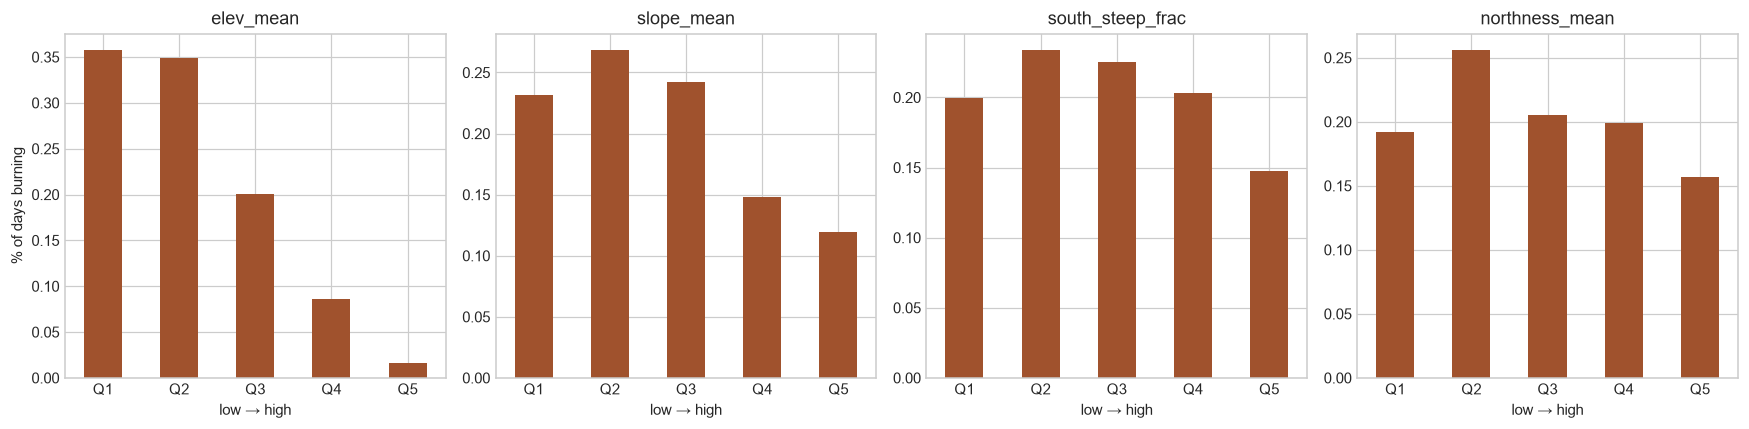

Rank correlation with fire rate (Spearman):
elev_mean          -0.67
elev_std           -0.27
slope_mean         -0.20
south_steep_frac   -0.07
northness_mean     -0.07
slope_max           0.02
dtype: float64


In [9]:
cell_rate = (panel.groupby("cell_id")["fire"].mean() * 100).rename("fire_rate")  # percent of days each cell was burning
cells = terrain.merge(cell_rate, left_on="cell_id", right_index=True)  # one row per cell: terrain + fire rate

features = ["elev_mean", "slope_mean", "south_steep_frac", "northness_mean"]  # the terrain features to test
fig, axes = plt.subplots(1, 4, figsize=(16, 4))  # four charts side by side
for ax, f in zip(axes, features):  # one chart per feature
    bins = pd.qcut(cells[f], 5, duplicates="drop")  # split cells into 5 equal-size groups by this feature
    cells.groupby(bins, observed=True)["fire_rate"].mean().plot(kind="bar", ax=ax, color="sienna")  # average fire rate per group
    ax.set_title(f)  # feature name as the title
    ax.set_xlabel("low → high")  # groups go from lowest to highest values
    ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4", "Q5"][: len(ax.get_xticklabels())], rotation=0)  # short group names instead of long ranges
axes[0].set_ylabel("% of days burning")  # y-axis label on the first chart only
save_fig("04_terrain_vs_fire")  # save for the README
plt.show()  # display the charts

print("Rank correlation with fire rate (Spearman):")  # header
print(cells[features + ["elev_std", "slope_max"]].corrwith(cells["fire_rate"], method="spearman").round(2).sort_values())  # how strongly each feature moves with fire rate, -1 to +1

**Finding:** Elevation is the strongest terrain signal (Spearman −0.67): low cells burn ~25× more often than the highest.
Slope (−0.20) is mostly confounded with elevation. South-facing steep share shows no clear link alone (−0.07) → keep it, let the model and SHAP judge interactions.
Caution: low elevation also means more people, so part of this is human ignition, not terrain.

## 7. Vegetation (NDVI) vs fire

In [10]:
nd = ndvi.dropna(subset=["ndvi"])[["cell_id", "end_date", "ndvi"]].copy()  # valid NDVI values only, with the date each became available
nd["end_date"] = nd["end_date"].astype("datetime64[ns]")  # same date precision as the panel, or merge_asof refuses to join
panel["date"] = panel["date"].astype("datetime64[ns]")  # same precision on the panel side
panel = panel.drop(columns=["ndvi", "end_date"], errors="ignore")  # remove old columns if this cell was run before

panel = pd.merge_asof(  # for each cell-day, take the latest NDVI whose end_date is on or before that day
    panel.sort_values("date"),  # left table must be sorted by its date
    nd.sort_values("end_date"),  # right table must be sorted by its date
    left_on="date",  # the day we predict from
    right_on="end_date",  # the day the NDVI value became known
    by="cell_id",  # only match within the same cell
    direction="backward",  # look back in time only, never forward (no leakage)
)  # end of merge_asof
panel["ndvi_age"] = (panel["date"] - panel["end_date"]).dt.days  # how many days old the NDVI value is
panel = panel.sort_values(["cell_id", "date"]).reset_index(drop=True)  # restore the cell-then-day order

print(f"Rows without NDVI (before the first composite): {panel['ndvi'].isna().sum():,}")  # should be very few
print("NDVI age in days:")  # header
print(panel["ndvi_age"].describe().round(1))  # usually 0–16 days old; the 2025 gap shows up as a large max

Rows without NDVI (before the first composite): 16,173
NDVI age in days:
count    2614635.0
mean           5.4
std           13.1
min            0.0
25%            2.0
50%            4.0
75%            6.0
max          167.0
Name: ndvi_age, dtype: float64


Saved 05_ndvi_vs_fire


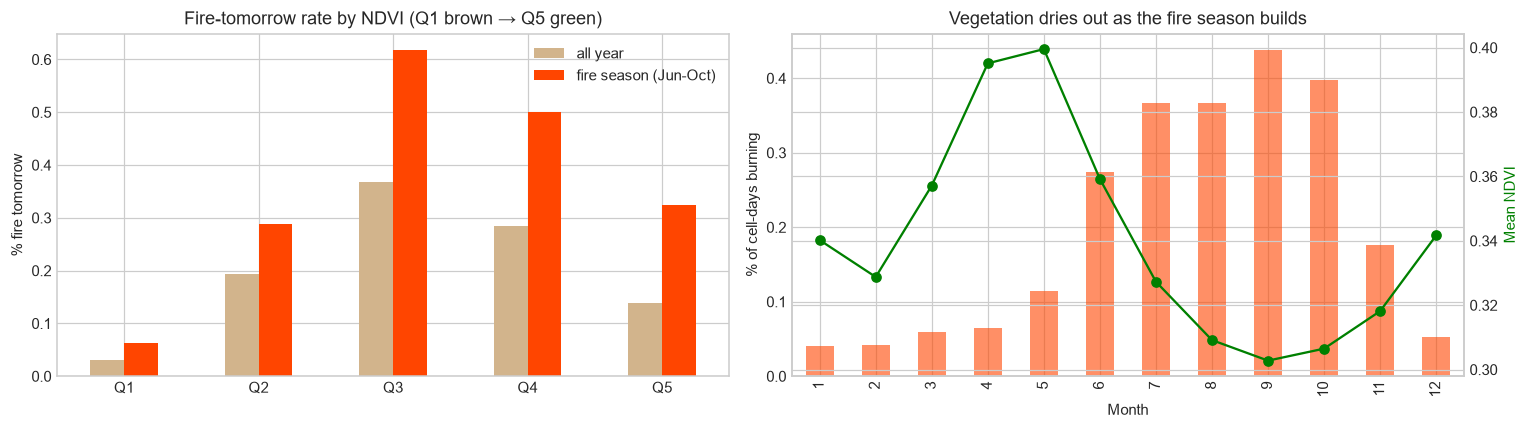

        all year  fire season (Jun-Oct)
ndvi_q                                 
Q1         0.031                  0.063
Q2         0.193                  0.288
Q3         0.369                  0.618
Q4         0.285                  0.501
Q5         0.138                  0.324


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))  # two charts side by side

panel["ndvi_q"] = pd.qcut(panel["ndvi"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])  # NDVI quintiles: Q1 = brownest, Q5 = greenest
season = panel["date"].dt.month.between(6, 10)  # June to October
by_q = pd.DataFrame({  # fire-tomorrow rate per NDVI group, two ways
    "all year": panel.groupby("ndvi_q", observed=True)["fire_tomorrow"].mean() * 100,  # every day
    "fire season (Jun-Oct)": panel[season].groupby("ndvi_q", observed=True)["fire_tomorrow"].mean() * 100,  # only in-season days
})  # end of table
by_q.plot(kind="bar", ax=axes[0], color=["tan", "orangered"], rot=0)  # grouped bars
axes[0].set_title("Fire-tomorrow rate by NDVI (Q1 brown → Q5 green)")  # title
axes[0].set_ylabel("% fire tomorrow")  # y-axis label
axes[0].set_xlabel("")  # group names explain themselves

month = panel["date"].dt.month  # calendar month of each row
(panel.groupby(month)["fire"].mean() * 100).plot(kind="bar", ax=axes[1], color="orangered", alpha=0.6)  # fire rate per month as bars
axes[1].set_ylabel("% of cell-days burning")  # left y-axis label
axes[1].set_xlabel("Month")  # x-axis label
ax2 = axes[1].twinx()  # second y-axis on the right, sharing the same months
ax2.plot(range(12), panel.groupby(month)["ndvi"].mean().values, color="green", marker="o")  # average NDVI per month as a green line
ax2.set_ylabel("Mean NDVI", color="green")  # right y-axis label
axes[1].set_title("Vegetation dries out as the fire season builds")  # title

save_fig("05_ndvi_vs_fire")  # save for the README
plt.show()  # display the charts
print(by_q.round(3))  # the numbers behind the left chart

**Finding:** NDVI vs fire is a hump: medium vegetation (Q3) burns ~10× more than bare land (Q1) in season, and ~2× more than the greenest cells (Q5) → fuel-limited at low NDVI, moisture-limited at high NDVI. Favors tree models (LightGBM) over linear ones.
NDVI peaks in May and bottoms in Sep, exactly when fires peak → Day 7: NDVI drop from spring peak (vegetation drying).
3 cells never have valid NDVI (coastal slivers); NDVI is median 4 days old; max 167 days = known 2025 gap.

## 8. Weather vs fire (2012–2015 only, rerun when download completes)

Season cell-days with weather: 286,722 | fire days: 932
Saved 06_weather_vs_fire


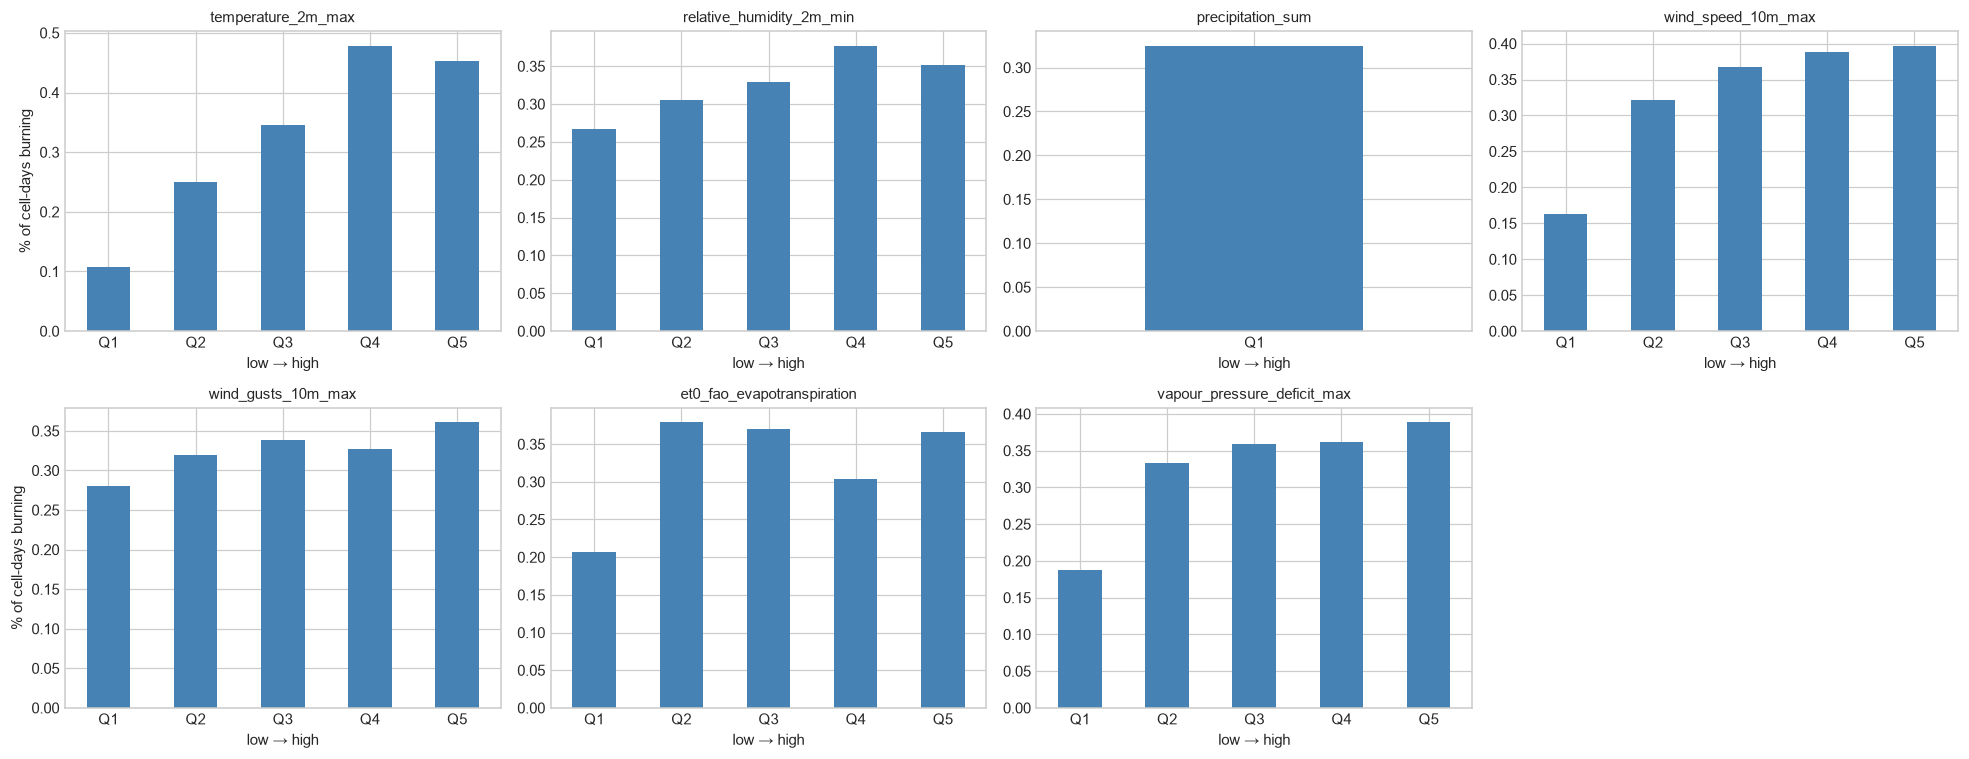

                             no fire   fire  fire / no fire
temperature_2m_max             27.20  28.70            1.06
relative_humidity_2m_min       37.00  39.00            1.05
precipitation_sum               0.00   0.00             NaN
wind_speed_10m_max             12.20  13.00            1.07
wind_gusts_10m_max             34.20  34.90            1.02
et0_fao_evapotranspiration      5.21   5.29            1.02
vapour_pressure_deficit_max     2.09   2.24            1.07


In [12]:
weather["date"] = weather["date"].astype("datetime64[ns]")  # same date precision as the panel
wx_cols = ["temperature_2m_max", "relative_humidity_2m_min", "precipitation_sum", "wind_speed_10m_max",  # the 7 weather variables (part 1)
           "wind_gusts_10m_max", "et0_fao_evapotranspiration", "vapour_pressure_deficit_max"]  # (part 2)
wx = panel.merge(weather, on=["cell_id", "date"], how="inner")  # keep only cell-days that have weather (2012–2015 for now)
wx = wx[wx["date"].dt.month.between(6, 10)]  # fire season only, so we compare like with like
print(f"Season cell-days with weather: {len(wx):,} | fire days: {int(wx['fire'].sum()):,}")  # sample size behind the charts

fig, axes = plt.subplots(2, 4, figsize=(18, 7))  # 8 slots for 7 charts
for ax, col in zip(axes.flat, wx_cols):  # one chart per weather variable
    bins = pd.qcut(wx[col], 5, duplicates="drop")  # 5 equal-size groups by this variable
    rate = wx.groupby(bins, observed=True)["fire"].mean() * 100  # same-day fire rate per group
    rate.plot(kind="bar", ax=ax, color="steelblue")  # bar per group
    ax.set_title(col, fontsize=10)  # variable name
    ax.set_xticklabels([f"Q{i + 1}" for i in range(len(rate))], rotation=0)  # short group names; rain may have fewer groups because of many 0s
    ax.set_xlabel("low → high")  # direction of the groups
axes.flat[-1].set_axis_off()  # hide the empty 8th slot
axes[0, 0].set_ylabel("% of cell-days burning")  # y-axis label on the left charts
axes[1, 0].set_ylabel("% of cell-days burning")  # same for the bottom row
save_fig("06_weather_vs_fire")  # save for the README
plt.show()  # display the charts

summary = wx.groupby("fire")[wx_cols].median().T  # median of each variable on non-fire (0) and fire (1) days
summary.columns = ["no fire", "fire"]  # readable column names
summary["fire / no fire"] = (summary["fire"] / summary["no fire"]).round(2)  # how much higher or lower on fire days
print(summary.round(2))  # the comparison table

Saved 07_weather_anomaly_vs_fire


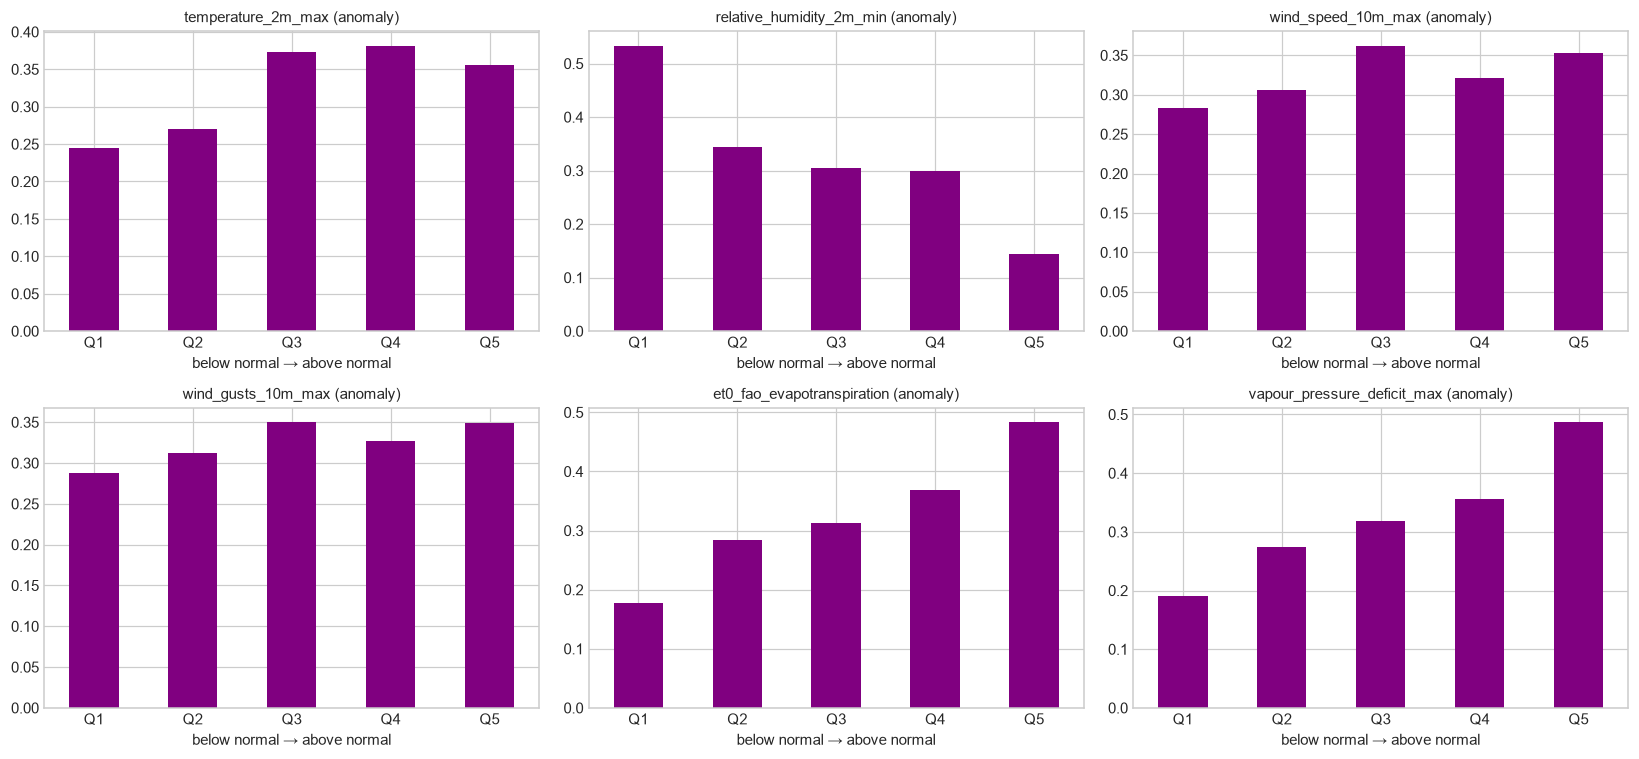

                                  no fire  fire
temperature_2m_max_anom             -0.00  0.42
relative_humidity_2m_min_anom        0.01 -4.20
wind_speed_10m_max_anom             -0.00  0.24
wind_gusts_10m_max_anom             -0.00  0.36
et0_fao_evapotranspiration_anom     -0.00  0.21
vapour_pressure_deficit_max_anom    -0.00  0.21


In [13]:
anom_cols = [c for c in wx_cols if c != "precipitation_sum"]  # every variable except rain (almost always 0 in season)
month = wx["date"].dt.month  # calendar month of each row
for col in anom_cols:  # build one anomaly column per variable
    normal = wx.groupby(["cell_id", month])[col].transform("mean")  # this cell's average for this month (EDA only; Day 7 must use past data only)
    wx[f"{col}_anom"] = wx[col] - normal  # how far today is from this cell's normal

fig, axes = plt.subplots(2, 3, figsize=(15, 7))  # 6 charts
for ax, col in zip(axes.flat, anom_cols):  # one chart per variable
    a = f"{col}_anom"  # the anomaly column name
    rate = wx.groupby(pd.qcut(wx[a], 5), observed=True)["fire"].mean() * 100  # fire rate per anomaly quintile
    rate.plot(kind="bar", ax=ax, color="purple")  # bar per group
    ax.set_title(f"{col} (anomaly)", fontsize=10)  # title
    ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4", "Q5"], rotation=0)  # short group names
    ax.set_xlabel("below normal → above normal")  # direction of the groups
save_fig("07_weather_anomaly_vs_fire")  # save for the README
plt.show()  # display the charts

diff = wx.groupby("fire")[[f"{c}_anom" for c in anom_cols]].mean().T  # average anomaly on non-fire (0) and fire (1) days
diff.columns = ["no fire", "fire"]  # readable column names
print(diff.round(2))  # positive on fire days = hotter, windier, drier than that cell's normal

**Finding:** Raw weather vs fire is mostly geography (cool = mountains, humid = coast). Against each cell's own monthly normal, the signal is clear:
humidity below normal → 3.7× more fires (−4.2 points on fire days); VPD and ET0 above normal → ~2.5×; temperature moderate; wind weak.
Rain is ~always 0 in season.
→ Day 7: weather anomaly features (past-only climatology) + days since last rain. Rerun with full 2012–2026 weather.

## 9. Data-quality traps

In [14]:
real["year"] = real["acq_date"].dt.year  # year of each real (non-hotspot) detection
print("Detections by source and year (last 4 years):")  # header
print(pd.crosstab(real["year"], real["source"]).tail(4))  # how many detections came from each source per year

aug_oct = real[real["acq_date"].dt.month.between(8, 10)]  # only Aug–Oct, the months NRT covers in 2026
per_fire_day = aug_oct.groupby([aug_oct["year"], "source"]).apply(lambda d: len(d) / d[["cell_id", "acq_date"]].drop_duplicates().shape[0])  # detections per burning cell-day: does NRT see fires as bigger or smaller?
print("\nAug–Oct detections per fire cell-day:")  # header
print(per_fire_day.round(2).tail(6))  # compare recent archive years with 2026 NRT
print("\nMedian FRP (fire intensity) by source:", real.groupby("source")["frp"].median().round(1).to_dict())  # is NRT intensity similar to archive?

cells_lf = grid[["cell_id", "land_frac"]].merge(cell_rate, left_on="cell_id", right_index=True)  # land share + fire rate per cell
lf_bins = pd.cut(cells_lf["land_frac"], [0, 0.25, 0.5, 0.75, 0.99, 1.0])  # groups from mostly-sea to fully land
print("\nFire rate (% of days) by land fraction:")  # header
print(cells_lf.groupby(lf_bins, observed=True)["fire_rate"].agg(["count", "mean"]).round(3))  # number of cells and average fire rate per group

print("\nMissing values in the panel:")  # header
print(panel.isna().sum()[panel.isna().sum() > 0])  # only columns with gaps

Detections by source and year (last 4 years):
source  VIIRS_SNPP_NRT  VIIRS_SNPP_SP
year                                 
2023                 0            577
2024                 0           1326
2025                 0            543
2026               324            226

Aug–Oct detections per fire cell-day:
year  source        
2021  VIIRS_SNPP_SP     1.71
2022  VIIRS_SNPP_SP     1.45
2023  VIIRS_SNPP_SP     1.99
2024  VIIRS_SNPP_SP     2.00
2025  VIIRS_SNPP_SP     1.55
2026  VIIRS_SNPP_NRT    1.81
dtype: float64

Median FRP (fire intensity) by source: {'VIIRS_SNPP_NRT': 4.5, 'VIIRS_SNPP_SP': 4.4}

Fire rate (% of days) by land fraction:
              count   mean
land_frac                 
(0.0, 0.25]      53  0.120
(0.25, 0.5]      27  0.181
(0.5, 0.75]      29  0.323
(0.75, 0.99]     36  0.270
(0.99, 1.0]     343  0.199

Missing values in the panel:
end_date    16173
ndvi        16173
ndvi_age    16173
ndvi_q      16173
dtype: int64


**Finding:** FIRMS archive → NRT switch (Aug 2026) is safe: detections per fire day (1.81 vs 1.45–2.00) and FRP (4.5 vs 4.4) match.
Mostly-sea cells burn less (0.12%), half-land coastal cells burn most (0.32%) → `land_frac` as a feature.
Only missing data: 3 coastal cells with no valid NDVI (LightGBM handles NaN).